# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [15]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [16]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [17]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

from tqdm import tqdm

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, images_per_row=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=images_per_row, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/images_per_row*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [18]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn = nn.BatchNorm2d(num_features=out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        conv_out = self.conv(x)
        bn_out = self.bn(conv_out)
        out = self.gelu(bn_out)
        return out
        # ===== end of code ====


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.down_conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)
        self.bn = nn.BatchNorm2d(num_features=out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        conv_out = self.down_conv(x)
        bn_out = self.bn(conv_out)
        out = self.gelu(bn_out)
        return out
        # ===== end of code ====


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.up_conv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)
        self.bn = nn.BatchNorm2d(num_features=out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        conv_out = self.up_conv(x)
        bn_out = self.bn(conv_out)
        out = self.gelu(bn_out)
        return out
        # ===== end of code ====


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.pool = nn.AvgPool2d(kernel_size=7)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.pool(x)
        # ===== end of code ====


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        # Unflatten has the same dimensions of input and output channels
        self.up_conv = nn.ConvTranspose2d(in_channels, out_channels=in_channels, kernel_size=7, stride=7, padding=0)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.up_conv(x)
        # ===== end of code ====


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv1 = Conv(in_channels, out_channels)
        self.conv2 = Conv(in_channels=out_channels, out_channels=out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        conv1_out = self.conv1(x)
        out = self.conv2(conv1_out)
        return out
        # ===== end of code ====


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.down_conv = DownConv(in_channels, out_channels)
        self.conv = Conv(in_channels=out_channels, out_channels=out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        out = self.down_conv(x)
        out = self.conv(out)
        return out
        # ===== end of code ====


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.up_conv = UpConv(in_channels, out_channels)
        self.conv = Conv(in_channels=out_channels, out_channels=out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        out = self.up_conv(x)
        out = self.conv(out)
        return out
        # ===== end of code ====


## Implementing Unconditional UNet

In [19]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.conv_block1 = ConvBlock(in_channels, num_hiddens)
        self.downblock1 = DownBlock(num_hiddens, num_hiddens)
        self.downblock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        self.flatten = Flatten()
        self.unflatten = Unflatten(in_channels = 2 * num_hiddens)
        self.upblock1 = UpBlock(in_channels=4 * num_hiddens, out_channels=num_hiddens)
        self.upblock2 = UpBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.conv_block2 = ConvBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.final_conv = nn.Conv2d(in_channels=num_hiddens, out_channels=1, kernel_size=3, stride=1, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        debug = False
        conv1_out = self.conv_block1(x)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block1: {conv1_out.shape}")
        down1_out = self.downblock1(conv1_out)  # (D, 14, 14)
        if debug:
            print(f"Shape after downblock1: {down1_out.shape}")
        down2_out = self.downblock2(down1_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after downblock2: {down2_out.shape}")

        flatten_out = self.flatten(down2_out)  # (2D, 1, 1)
        if debug:
            print(f"Shape after flatten: {flatten_out.shape}")
        unflatten_out = self.unflatten(flatten_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after unflatten: {unflatten_out.shape}")

        concat1 = torch.cat((down2_out, unflatten_out), dim=1)  # (4D, 7, 7)
        if debug:
            print(f"Shape after concat1: {concat1.shape}")

        upblock_out1 = self.upblock1(concat1)  # (D, 14, 14)
        if debug:
            print(f"Shape after upblock_out1: {upblock_out1.shape}")
        concat2 = torch.cat((down1_out, upblock_out1), dim=1)  # (2D, 14, 14)
        if debug:
            print(f"Shape after concat2: {concat2.shape}")

        upblock_out2 = self.upblock2(concat2)  # (D, 28, 28)
        if debug:
            print(f"Shape after upblock_out2: {upblock_out2.shape}")
        concat3 = torch.cat((conv1_out, upblock_out2), dim=1)  # (2D, 28, 28)
        if debug:
            print(f"Shape after concat3: {concat3.shape}")

        conv2_out = self.conv_block2(concat3)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block2: {conv2_out.shape}")
        out = self.final_conv(conv2_out)  # (D, 28, 28)
        return out
        # ===== end of code ====

In [20]:
unet = UnconditionalUNet(in_channels=1, num_hiddens=5)
gen = torch.Generator().manual_seed(SEED)
test_input = torch.rand((1, 1, 28, 28), generator=gen) # (28, 28) image of values from [0, 1]

test_output = unet(test_input)
print(f"Output shape: {test_output.shape}")

Output shape: torch.Size([1, 1, 28, 28])


# Part 1.2: Using the UNet to Train a Denoiser

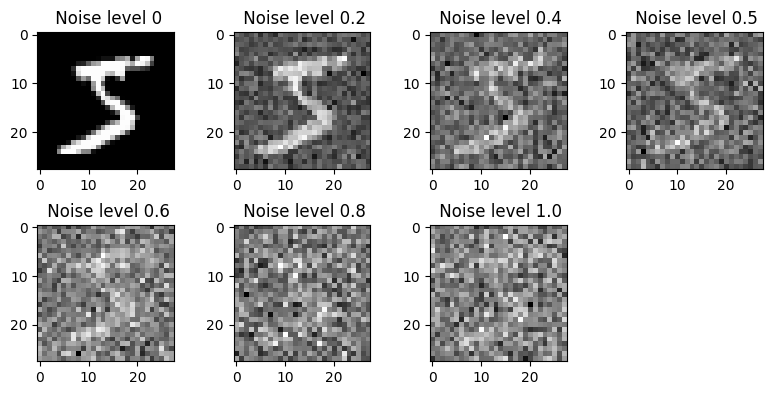

In [21]:
# Visualize images at different noisy level
# ===== your code here! ====
def add_noise(x, sigma):
    """z = x + sigma * noise"""
    noise = torch.randn(x.shape, device=x.device)
    return x + sigma * noise

img = train_dataset[0][0]
noisy_images = {}

for sigma in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    z = add_noise(img, sigma)
    noisy_images[sigma] = torch.permute(z, (1, 2, 0))  # plt.imshow expects (H, W, C)

fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(8, 4))
axs_flat = axs.flatten()
axs_flat[0].imshow(noisy_images[0], cmap="gray")
axs_flat[0].set_title(" Noise level 0")

axs_flat[1].imshow(noisy_images[0.2], cmap="gray")
axs_flat[1].set_title(" Noise level 0.2")

axs_flat[2].imshow(noisy_images[0.4], cmap="gray")
axs_flat[2].set_title(" Noise level 0.4")

axs_flat[3].imshow(noisy_images[0.5], cmap="gray")
axs_flat[3].set_title(" Noise level 0.5")

axs_flat[4].imshow(noisy_images[0.6], cmap="gray")
axs_flat[4].set_title(" Noise level 0.6")

axs_flat[5].imshow(noisy_images[0.8], cmap="gray")
axs_flat[5].set_title(" Noise level 0.8")

axs_flat[6].imshow(noisy_images[1.0], cmap="gray")
axs_flat[6].set_title(" Noise level 1.0")

for i, ax in enumerate(axs_flat):
    if i >= len(noisy_images):
        ax.set_visible(False)  # Hide extra unused plots

plt.tight_layout()
plt.show()
# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [22]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

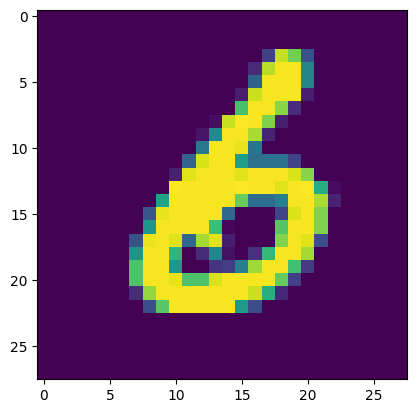

In [23]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
gen = torch.Generator().manual_seed(SEED)  # Set seeded generator for reproducibility
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, generator=gen)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

for x, y in train_loader:
    plt.imshow(torch.permute(x[0], (1, 2, 0)))
    break


In [24]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

In [25]:
# The training loops
train_losses = []
test_losses = []
test_results_by_epoch = {}

for epoch in range(num_epochs):
    model.to(device)
    model.train()
    print(f"Beginning epoch {epoch + 1}/{num_epochs}")
    for i, (images, _) in enumerate(tqdm(train_loader)):
        # ===== your code here! ====

        # Add noise with sigma noise_level to the clean image
        images = images.to(device)
        inputs = add_noise(images, sigma=noise_level)
        # Use UNet to predict original image from noisy image
        outputs = model(inputs)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
    model.eval()
    test_results = {
        "clean": [],
        "input": [],
        "prediction": []
    }
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            inputs = add_noise(images, sigma=noise_level)
            outputs = model(inputs)

            test_loss = criterion(outputs, images)
            test_losses.append(test_loss.item())

            test_results["clean"].extend(images)
            test_results["input"].extend(inputs)
            test_results["prediction"].extend(outputs)

    test_results_by_epoch[epoch] = test_results

Beginning epoch 1/5


100%|██████████| 235/235 [01:39<00:00,  2.37it/s]


Evaluating model on test set after epoch 1/5
Beginning epoch 2/5


100%|██████████| 235/235 [01:23<00:00,  2.82it/s]


Evaluating model on test set after epoch 2/5
Beginning epoch 3/5


...

Evaluating model on test set after epoch 3/5
Beginning epoch 4/5


100%|██████████| 235/235 [01:23<00:00,  2.81it/s]


Evaluating model on test set after epoch 4/5
Beginning epoch 5/5


100%|██████████| 235/235 [01:23<00:00,  2.82it/s]


Evaluating model on test set after epoch 5/5


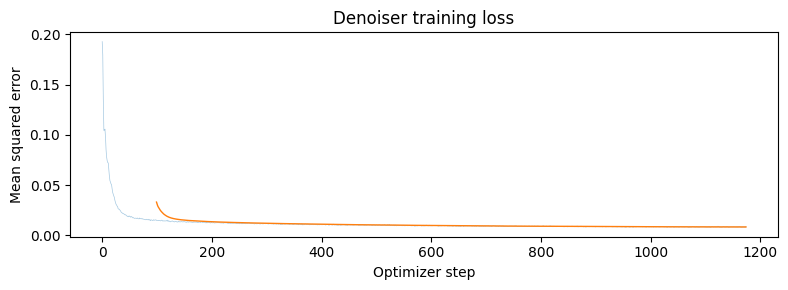

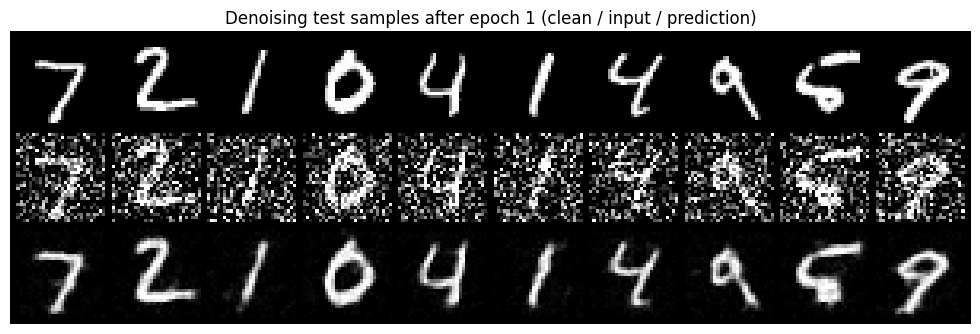

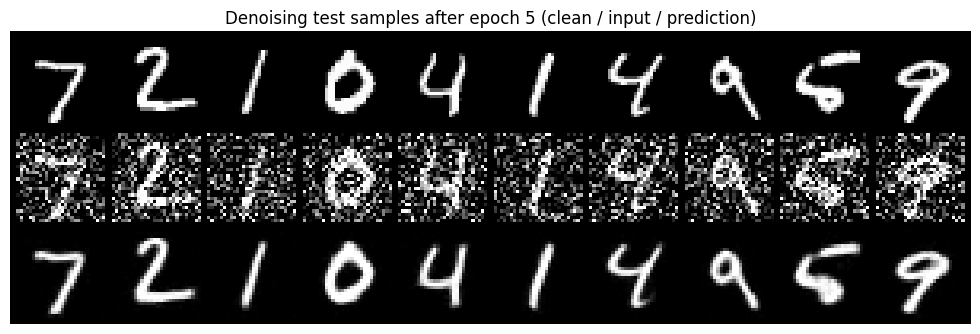

In [26]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "Denoiser training loss")

first_epoch = test_results_by_epoch[0]
first_epoch_images = torch.stack([*first_epoch["clean"][:10], *first_epoch["input"][:10], *first_epoch["prediction"][:10]])
show_grid(first_epoch_images, "Denoising test samples after epoch 1 (clean / input / prediction)", "denoise_epoch1.jpg", images_per_row=10)

last_epoch = test_results_by_epoch[4]
last_epoch_images =  torch.stack([*last_epoch["clean"][:10], *last_epoch["input"][:10], *last_epoch["prediction"][:10]])
show_grid(last_epoch_images, "Denoising test samples after epoch 5 (clean / input / prediction)", "denoise_epoch5.jpg", images_per_row=10)
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

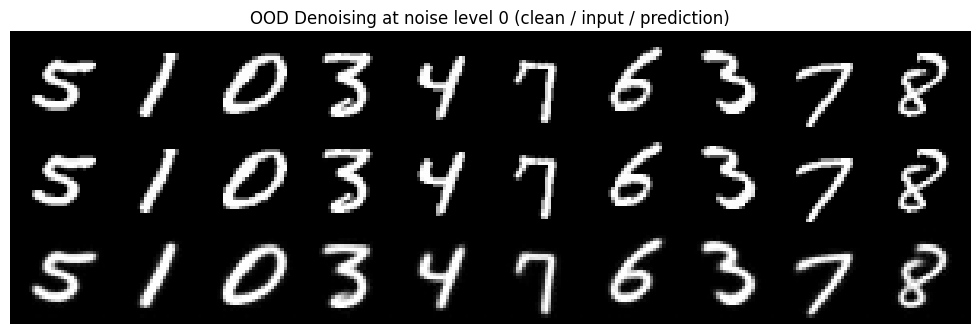

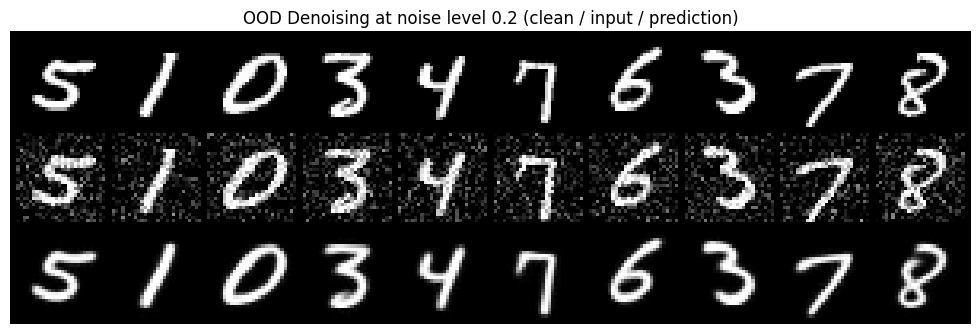

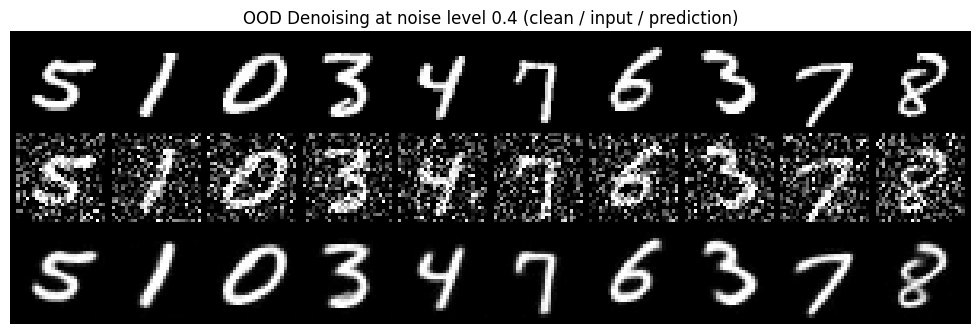

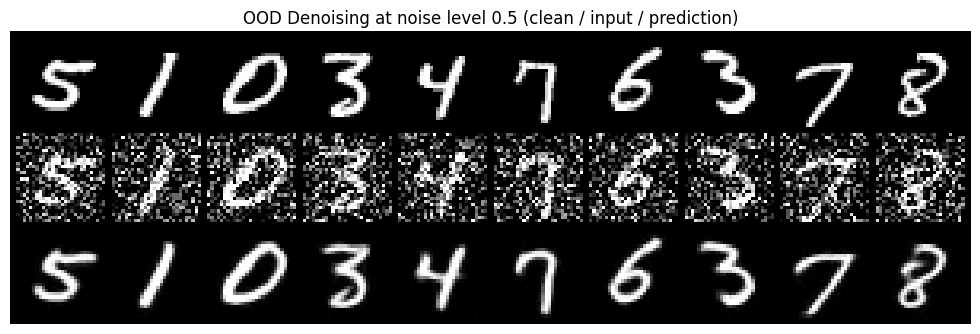

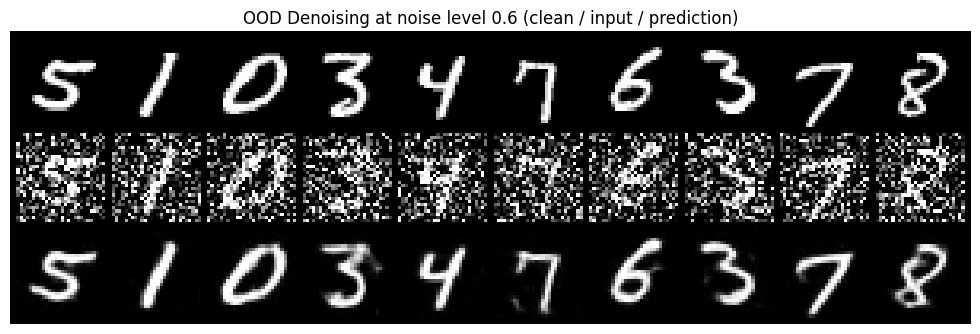

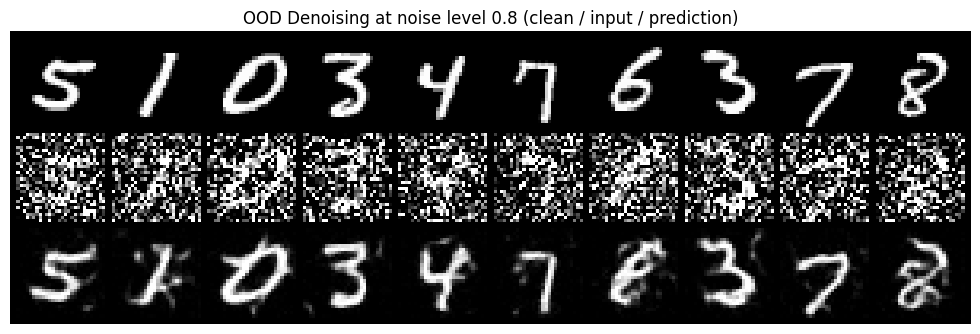

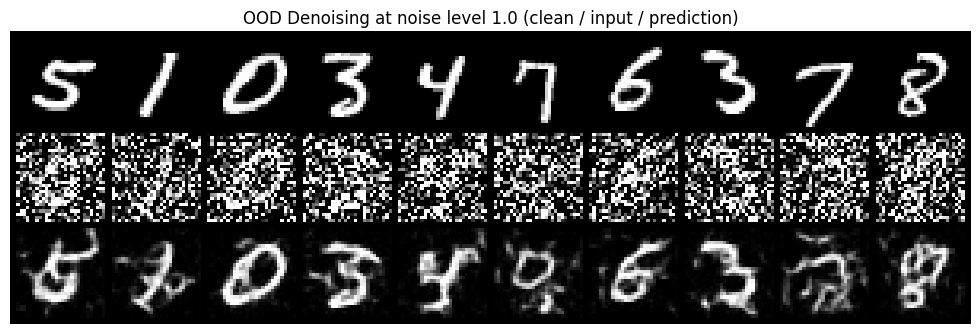

In [27]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()

sample_idx = torch.randint(high=len(test_dataset), size=(10,))

test_samples = torch.stack([test_dataset[i][0] for i in sample_idx])
test_samples = test_samples.to(device)

ood_results = {}

for sigma in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    curr_noise_level_results = {
        "clean": [],
        "input": [],
        "prediction": []
    }

    inputs = add_noise(test_samples, sigma)
    outputs = model(inputs)

    curr_noise_level_results["clean"] = test_samples
    curr_noise_level_results["input"] = inputs
    curr_noise_level_results["prediction"] = outputs

    images_to_display = torch.cat((test_samples, inputs, outputs), dim=0)
    show_grid(images_to_display, f"OOD Denoising at noise level {sigma} (clean / input / prediction)", f"ood_denoise_{sigma}.jpg", images_per_row=10)

# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

In [28]:
def train(model, optimizer, criterion, num_epochs, noise_level):
  train_losses = []
  test_losses = []
  test_results_by_epoch = {}

  for epoch in range(num_epochs):
      model.to(device)
      model.train()
      print(f"Beginning epoch {epoch + 1}/{num_epochs}")
      for i, (images, _) in enumerate(tqdm(train_loader)):

          # Add noise with sigma noise_level to the clean image
          images = images.to(device)
          inputs = add_noise(images, sigma=noise_level)
          # Predict original image from noisy image
          outputs = model(inputs)

          loss = criterion(outputs, images)
          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

          train_losses.append(loss.item())

      print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
      model.eval()
      test_results = {
          "clean": [],
          "input": [],
          "prediction": []
      }
      with torch.no_grad():
          for images, _ in test_loader:
              images = images.to(device)
              inputs = add_noise(images, sigma=noise_level)
              outputs = model(inputs)

              test_loss = criterion(outputs, images)
              test_losses.append(test_loss.item())

              test_results["clean"].extend(images)
              test_results["input"].extend(inputs)
              test_results["prediction"].extend(outputs)

      test_results_by_epoch[epoch] = test_results
  return train_losses, test_losses, test_results_by_epoch


Beginning epoch 1/5


100%|██████████| 235/235 [01:23<00:00,  2.82it/s]


Evaluating model on test set after epoch 1/5
Beginning epoch 2/5


100%|██████████| 235/235 [01:23<00:00,  2.82it/s]


Evaluating model on test set after epoch 2/5
Beginning epoch 3/5


...

Evaluating model on test set after epoch 3/5
Beginning epoch 4/5


100%|██████████| 235/235 [01:23<00:00,  2.82it/s]


Evaluating model on test set after epoch 4/5
Beginning epoch 5/5


100%|██████████| 235/235 [01:23<00:00,  2.83it/s]


Evaluating model on test set after epoch 5/5


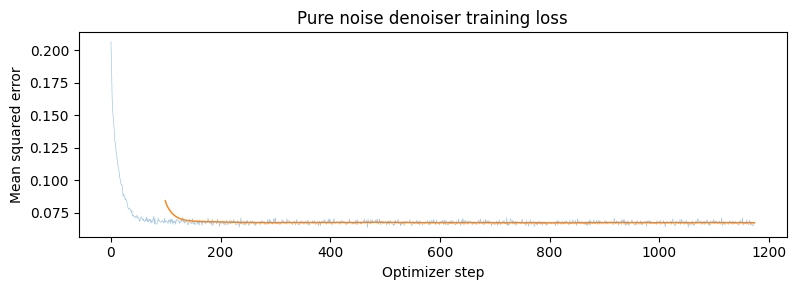

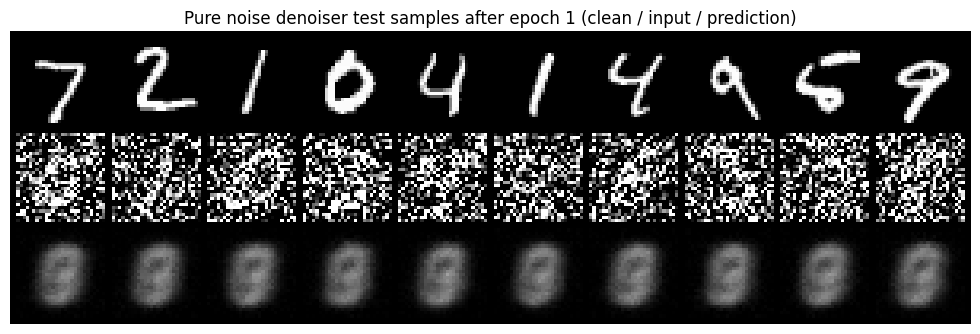

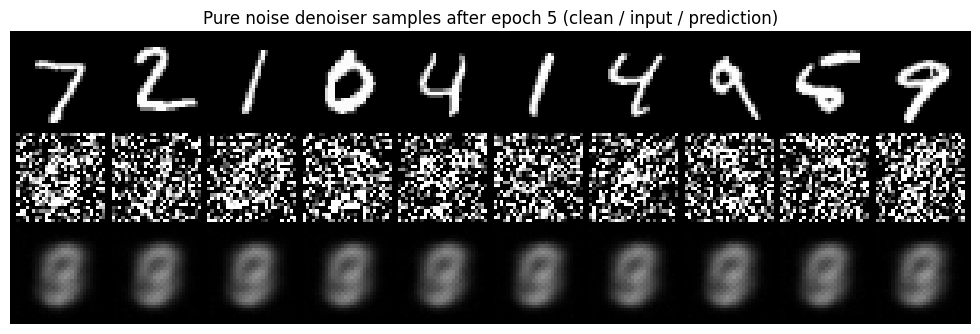

In [29]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.

dpn_model = UnconditionalUNet(in_channels=1, num_hiddens=128)
dpn_optimizer = torch.optim.Adam(dpn_model.parameters(), lr=1e-4)
dpn_criterion = nn.MSELoss()

# The training loops
dpn_train_losses = []
dpn_test_losses = []
dpn_test_results_by_epoch = {}

for epoch in range(5):
    dpn_model.to(device)
    dpn_model.train()
    print(f"Beginning epoch {epoch + 1}/{5}")
    for i, (images, _) in enumerate(tqdm(train_loader)):
        images = images.to(device)

        # Input is independent Gaussian noise
        pure_noise = torch.randn_like(images)
        pure_noise = pure_noise.to(device)
        outputs = dpn_model(pure_noise)

        loss = dpn_criterion(outputs, images)
        dpn_optimizer.zero_grad()
        loss.backward()
        dpn_optimizer.step()

        dpn_train_losses.append(loss.item())

    print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
    dpn_model.eval()
    test_results = {
        "clean": [],
        "input": [],
        "prediction": []
    }
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            pure_noise = torch.randn_like(images)
            outputs = dpn_model(pure_noise)

            test_loss = dpn_criterion(outputs, images)
            dpn_test_losses.append(test_loss.item())

            test_results["clean"].extend(images)
            test_results["input"].extend(inputs)
            test_results["prediction"].extend(outputs)

    dpn_test_results_by_epoch[epoch] = test_results

# Visualize your training curve
# ===== your code here! ====
loss_plot(dpn_train_losses, "Pure noise denoiser training loss")

dpn_first_epoch = torch.stack([*dpn_test_results_by_epoch[0]["clean"][:10], *dpn_test_results_by_epoch[0]["input"][:10], *dpn_test_results_by_epoch[0]["prediction"][:10]])
show_grid(dpn_first_epoch, "Pure noise denoiser test samples after epoch 1 (clean / input / prediction)", "dpn_epoch1.jpg", images_per_row=10)

dpn_last_epoch =  torch.stack([*dpn_test_results_by_epoch[4]["clean"][:10], *dpn_test_results_by_epoch[4]["input"][:10], *dpn_test_results_by_epoch[4]["prediction"][:10]])
show_grid(dpn_last_epoch, "Pure noise denoiser samples after epoch 5 (clean / input / prediction)", "dpn_epoch5.jpg", images_per_row=10)
# ===== end of code ====

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [30]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.linear1 = nn.Linear(in_channels, out_channels)
        self.gelu = nn.GELU()
        self.linear2 = nn.Linear(out_channels, out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        out1 = self.linear1(x)
        gelu_out = self.gelu(out1)
        out = self.linear2(gelu_out)

        return out
        # ===== end of code ====


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.conv_block1 = ConvBlock(in_channels, num_hiddens)
        self.downblock1 = DownBlock(num_hiddens, num_hiddens)
        self.downblock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        self.flatten = Flatten()
        self.unflatten = Unflatten(in_channels = 2 * num_hiddens)
        self.upblock1 = UpBlock(in_channels=4 * num_hiddens, out_channels=num_hiddens)
        self.upblock2 = UpBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.conv_block2 = ConvBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.final_conv = nn.Conv2d(in_channels=num_hiddens, out_channels=in_channels, kernel_size=3, stride=1, padding=1)

        self.fc1_t = FCBlock(in_channels=1, out_channels=2 * num_hiddens)
        self.fc2_t = FCBlock(in_channels=1, out_channels=num_hiddens)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t[:, None] # Reshape T from (N,) into (N, 1)
        t1 = self.fc1_t(t)[:, :, None, None]  # (N, 2D, 1, 1); Add 2 singleton dimensions at the end for broadcasting to 2D image
        t2 = self.fc2_t(t)[:, :, None, None]  # (N, D, 1, 1); Add 2 singleton dimensions at the end for broadcasting to 2D image

        debug = False
        conv1_out = self.conv_block1(x)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block1: {conv1_out.shape}")
        down1_out = self.downblock1(conv1_out)  # (D, 14, 14)
        if debug:
            print(f"Shape after downblock1: {down1_out.shape}")
        down2_out = self.downblock2(down1_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after downblock2: {down2_out.shape}")

        flatten_out = self.flatten(down2_out)  # (2D, 1, 1)
        if debug:
            print(f"Shape after flatten: {flatten_out.shape}")
        unflatten_out = self.unflatten(flatten_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after unflatten: {unflatten_out.shape}")
            print(f"Shape of t1 {t1.shape}")

        # Replace the original unflatten with modulated unflatten
        unflatten_out = unflatten_out * t1

        concat1 = torch.cat((down2_out, unflatten_out), dim=1)  # (4D, 7, 7)
        if debug:
            print(f"Shape after concat1: {concat1.shape}")

        upblock_out1 = self.upblock1(concat1)  # (D, 14, 14)
        if debug:
            print(f"Shape after upblock_out1: {upblock_out1.shape}")
            print(f"Shape of t2 {t2.shape}")

        # Replace the original up1 with modulated up1
        upblock_out1 = upblock_out1 * t2

        concat2 = torch.cat((down1_out, upblock_out1), dim=1)  # (2D, 14, 14)
        if debug:
            print(f"Shape after concat2: {concat2.shape}")

        upblock_out2 = self.upblock2(concat2)  # (D, 28, 28)
        if debug:
            print(f"Shape after upblock_out2: {upblock_out2.shape}")
        concat3 = torch.cat((conv1_out, upblock_out2), dim=1)  # (2D, 28, 28)
        if debug:
            print(f"Shape after concat3: {concat3.shape}")

        conv2_out = self.conv_block2(concat3)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block2: {conv2_out.shape}")
        out = self.final_conv(conv2_out)  # (D, 28, 28)

        return out
        # ===== end of code ====

In [31]:
# Sanity checking input/output shapes
tc_unet = TimeConditionalUNet(in_channels=1, num_classes=1, num_hiddens=5)
gen = torch.Generator().manual_seed(SEED)
test_input = torch.rand((2, 1, 28, 28), generator=gen) # (28, 28) image of values from [0, 1]
test_t = torch.ones((2,), dtype=torch.float32)

test_output = tc_unet(test_input, test_t)
print(f"Output shape: {test_output.shape}")

Output shape: torch.Size([2, 1, 28, 28])


## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [32]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    # ===== your code here! ====
    x0 = torch.randn_like(x_1)
    t = torch.rand(x_1.shape[0], device=x_1.device, dtype=x_1.dtype)  # (N, )
    t_broadcast = t[:, None, None, None]  # (N, 1, 1, 1)
    xt = (1 - t_broadcast) * x0 + t_broadcast * x_1

    pred_vel = unet(xt, t)
    true_vel = x_1 - x0

    loss = ((true_vel - pred_vel) ** 2).mean()

    return loss
    # ===== end of code ====

In [33]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_hw: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_hw: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    H, W = img_hw
    gen = torch.Generator(device=device).manual_seed(seed)
    x0 = torch.randn(size=(1, 1, H, W), device=device, generator=gen)

    step_size = 1.0 / num_ts
    xt = x0

    for step in range(num_ts):
      t = torch.tensor([step / num_ts], device=device)
      pred_vel = unet(xt, t)
      xt = xt + step_size * pred_vel

    return xt
    # ===== end of code ====

In [34]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_hw: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_hw, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

Beginning epoch 1/10


100%|██████████| 938/938 [00:36<00:00, 25.46it/s]


Evaluating model on test set after epoch 1/10


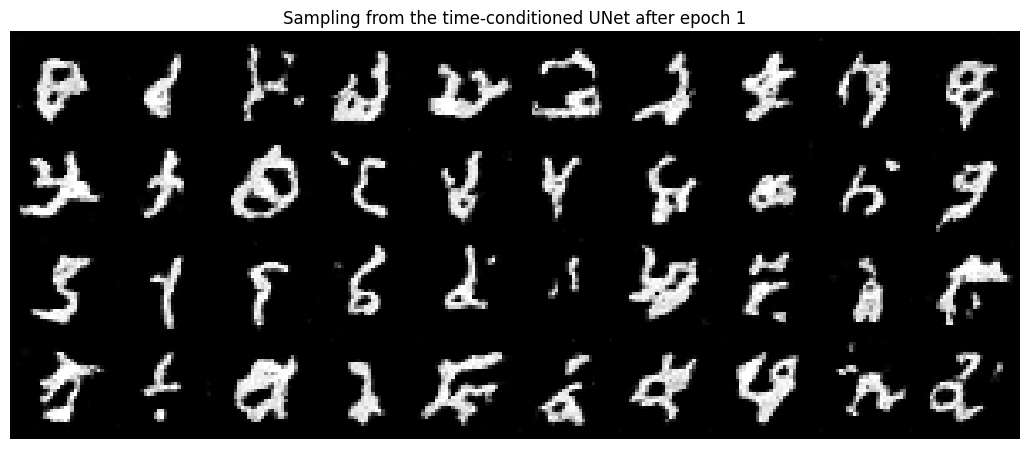

Beginning epoch 2/10


100%|██████████| 938/938 [00:36<00:00, 25.46it/s]


Evaluating model on test set after epoch 2/10


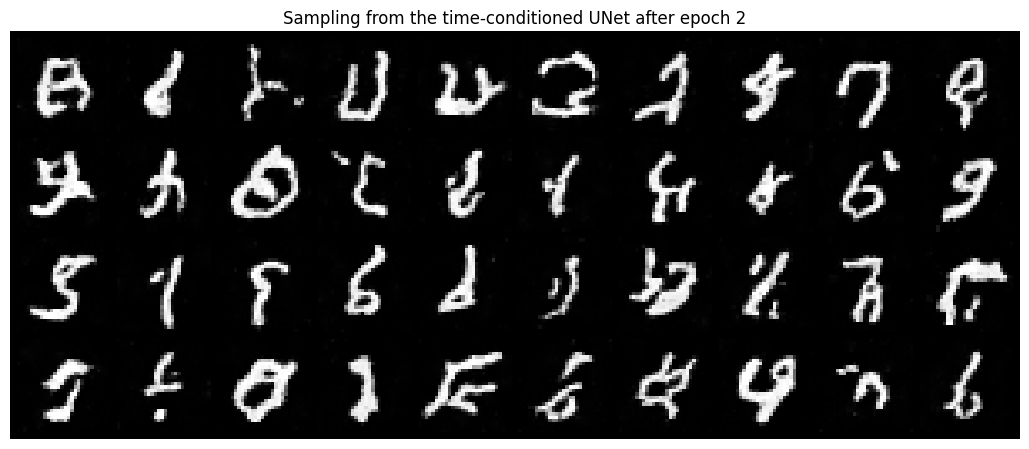

Beginning epoch 3/10


100%|██████████| 938/938 [00:36<00:00, 25.35it/s]


Evaluating model on test set after epoch 3/10


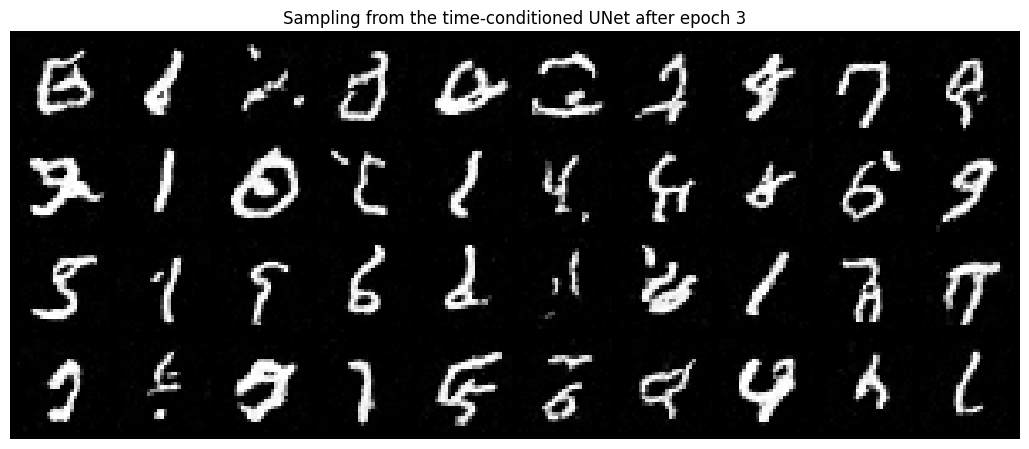

Beginning epoch 4/10


100%|██████████| 938/938 [00:37<00:00, 25.27it/s]


Evaluating model on test set after epoch 4/10


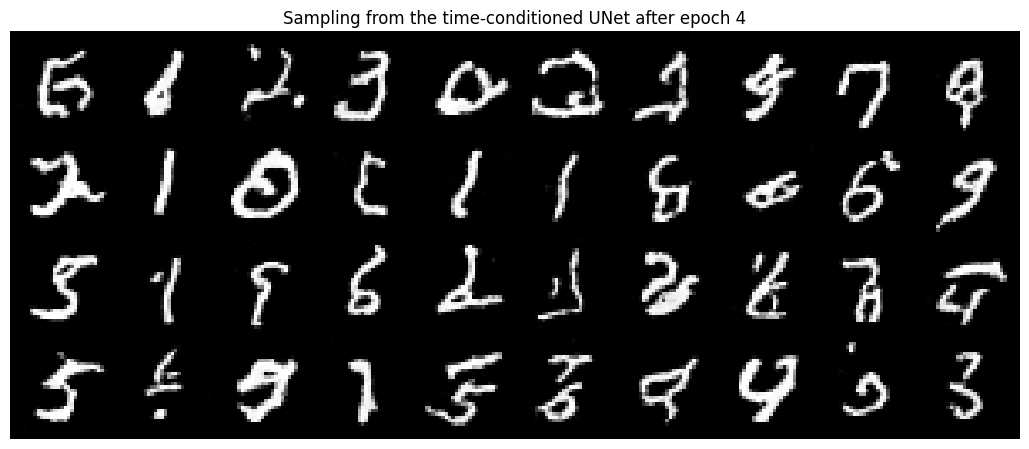

Beginning epoch 5/10


100%|██████████| 938/938 [00:37<00:00, 25.22it/s]


Evaluating model on test set after epoch 5/10


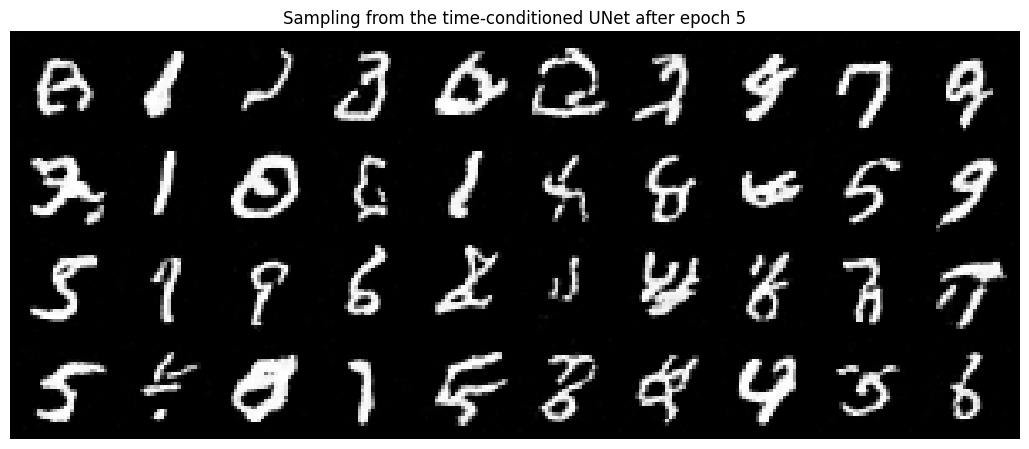

Beginning epoch 6/10


100%|██████████| 938/938 [00:37<00:00, 25.09it/s]


Evaluating model on test set after epoch 6/10


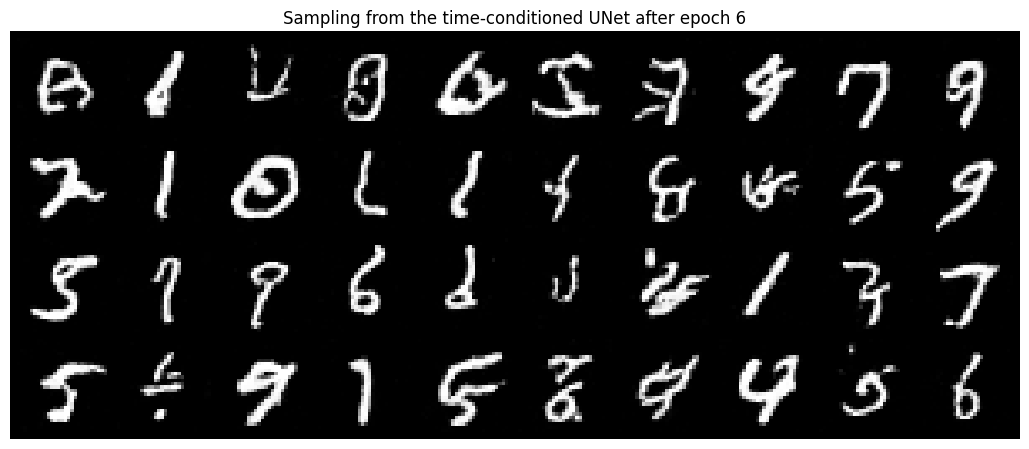

Beginning epoch 7/10


100%|██████████| 938/938 [00:37<00:00, 25.07it/s]


Evaluating model on test set after epoch 7/10


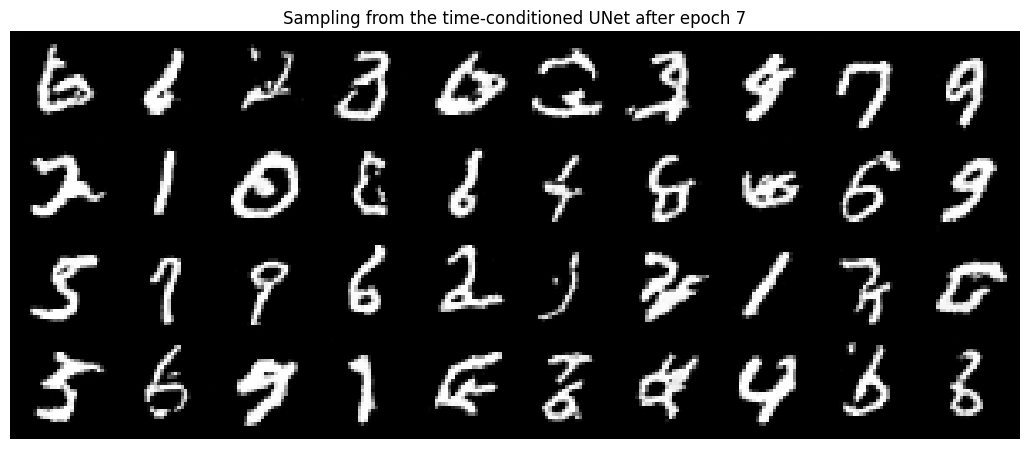

Beginning epoch 8/10


100%|██████████| 938/938 [00:37<00:00, 24.97it/s]


Evaluating model on test set after epoch 8/10


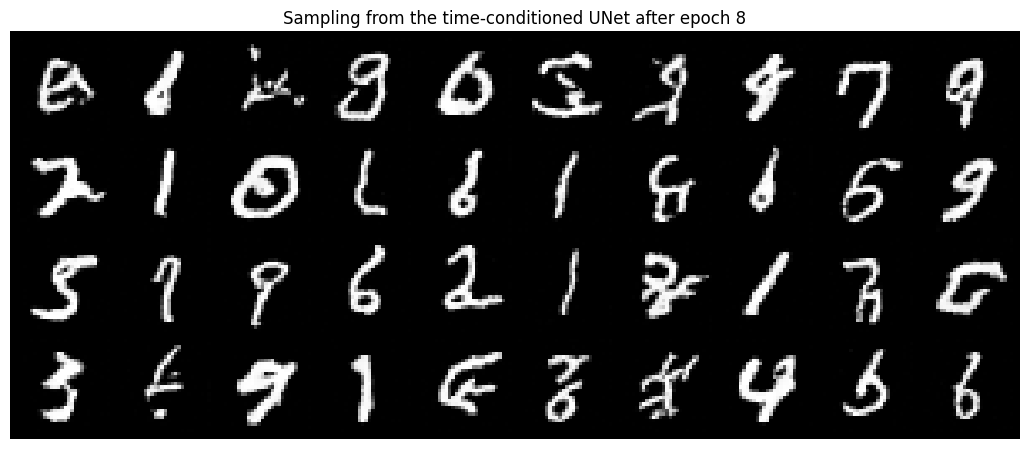

Beginning epoch 9/10


100%|██████████| 938/938 [00:37<00:00, 24.98it/s]


Evaluating model on test set after epoch 9/10


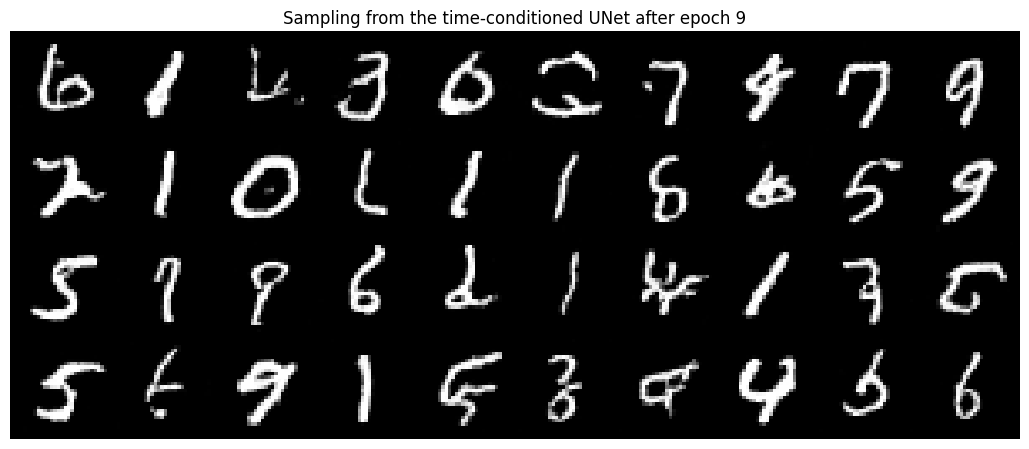

Beginning epoch 10/10


100%|██████████| 938/938 [00:37<00:00, 24.83it/s]


Evaluating model on test set after epoch 10/10


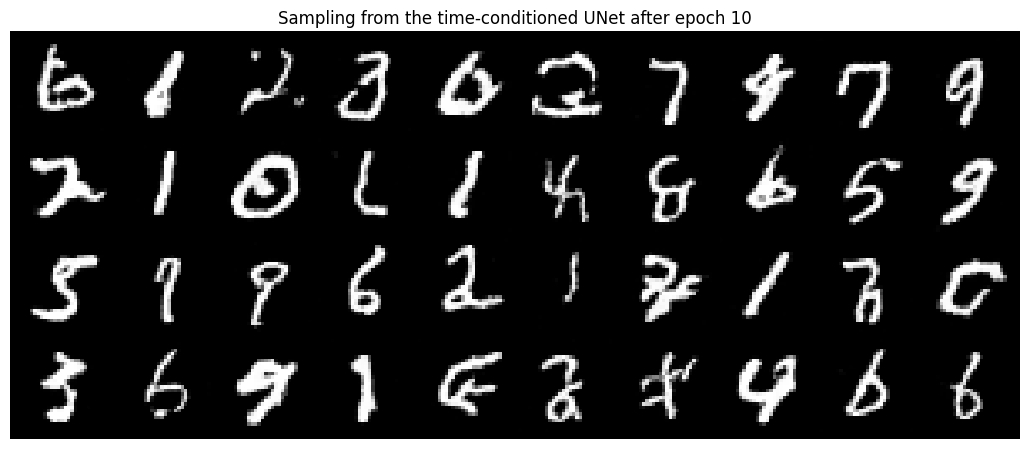

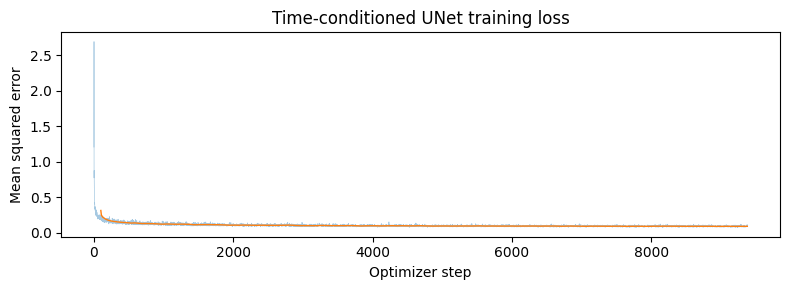

In [35]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====
# Set hyperparameters
batch_size = 64
learning_rate = 1e-2
hidden_dim = 64
num_epochs = 10

# Prepare data
gen = torch.Generator().manual_seed(SEED)  # Set seeded generator for reproducibility
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, generator=gen)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

# Initialize model
tc_unet = TimeConditionalUNet(in_channels=1, num_classes=1, num_hiddens=hidden_dim)
tcfm = TimeConditionalFM(tc_unet)
tcm = tcfm.to(device)
tcfm_optimizer = torch.optim.Adam(tcfm.parameters(), lr=learning_rate)
tcfm_scheduler = torch.optim.lr_scheduler.ExponentialLR(tcfm_optimizer, gamma=(0.1 ** (1.0 / num_epochs)))

tcfm_train_losses = []
tcfm_test_losses = []
tcfm_samples_by_epoch = {}
NUM_SAMPLES = 40  # Number of images to sample after each epoch

for epoch in range(num_epochs):
  tcfm.train()
  print(f"Beginning epoch {epoch + 1}/{num_epochs}")
  for i, (x1, _) in enumerate(tqdm(train_loader)):
    x1 = x1.to(device)

    tcfm_optimizer.zero_grad()
    loss = tcfm(x1)  # tcfm's forward performs forward passes and returns the loss
    loss.backward()
    tcfm_optimizer.step()

    tcfm_train_losses.append(loss.item())

  print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
  tcfm.eval()
  test_results = {
      "clean": [],
      "input": [],
      "prediction": []
  }
  with torch.no_grad():
      for x1, _ in test_loader:
        x1 = x1.to(device)
        # Perform forward pass and get the loss
        loss = tcfm(x1)
        tcfm_test_losses.append(loss.item())

      # Sample new images from the trained time-conditioned unet, starting from pure noise
      samples = []
      for i in range(NUM_SAMPLES):
          xt = tcfm.sample(img_hw=(28, 28), seed=SEED + i) # (1, 1, 28, 28)
          samples.append(xt)

      samples = torch.cat(samples, dim=0)
      show_grid(samples, f"Sampling from the time-conditioned UNet after epoch {epoch + 1}", f"tcfm_samples_epoch{epoch + 1}.jpg", images_per_row=10)
      tcfm_samples_by_epoch[epoch] = samples

  tcfm_scheduler.step()

loss_plot(tcfm_train_losses, "Time-conditioned UNet training loss")

# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

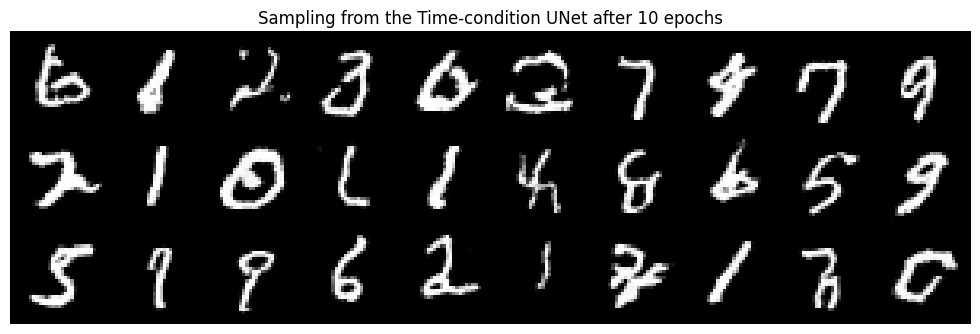

In [36]:
# Sampling from the UNet
# ===== your code here! ====
samples = []

for i in range(30):
    xt = tcfm.sample(img_hw=(28, 28), seed=SEED + i) # (1, 1, 28, 28)
    samples.append(xt)

samples = torch.cat(samples, dim=0)

show_grid(samples, f"Sampling from the Time-condition UNet after {num_epochs} epochs", "tc_unet_samples.jpg", images_per_row=10)
# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [37]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        self.in_channels = in_channels
        self.num_classes = num_classes

        self.conv_block1 = ConvBlock(in_channels, num_hiddens)
        self.downblock1 = DownBlock(num_hiddens, num_hiddens)
        self.downblock2 = DownBlock(num_hiddens, 2 * num_hiddens)
        self.flatten = Flatten()
        self.unflatten = Unflatten(in_channels = 2 * num_hiddens)
        self.upblock1 = UpBlock(in_channels=4 * num_hiddens, out_channels=num_hiddens)
        self.upblock2 = UpBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.conv_block2 = ConvBlock(in_channels=2 * num_hiddens, out_channels=num_hiddens)
        self.final_conv = nn.Conv2d(in_channels=num_hiddens, out_channels=in_channels, kernel_size=3, stride=1, padding=1)

        self.fc1_t = FCBlock(in_channels=1, out_channels=2 * num_hiddens)
        self.fc2_t = FCBlock(in_channels=1, out_channels=num_hiddens)
        self.fc1_c = FCBlock(in_channels=num_classes, out_channels=2 * num_hiddens)
        self.fc2_c = FCBlock(in_channels=num_classes, out_channels=num_hiddens)
        # ===== end of code ====


    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.to(device=x.device)
        t = t.reshape(-1, 1) # Reshape T from (N,) into (N, 1)

        c = c.to(device=x.device)
        c_one_hot = torch.zeros((c.shape[0], self.num_classes), device=x.device, dtype=x.dtype)  # (N, num_classes)
        c_one_hot.scatter_(dim=1, index=c.unsqueeze(1), value=1.0)  # Write 1's into the class positions

        # Apply unconditioning mask if it is not None
        if mask is not None:
            mask = mask.to(device=x.device).reshape(-1, 1)
            c_one_hot = c_one_hot * mask

        t1 = self.fc1_t(t)[:, :, None, None]  # (N, 2D, 1, 1); Add 2 singleton dimensions at the end for broadcasting to 2D image
        t2 = self.fc2_t(t)[:, :, None, None]  # (N, D, 1, 1); Add 2 singleton dimensions at the end for broadcasting to 2D image
        c1 = self.fc1_c(c_one_hot)[:, :, None, None]  # (N, 2D, 1, 1)
        c2 = self.fc2_c(c_one_hot)[:, :, None, None]  # (N, D, 1, 1)

        debug = False
        conv1_out = self.conv_block1(x)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block1: {conv1_out.shape}")
        down1_out = self.downblock1(conv1_out)  # (D, 14, 14)
        if debug:
            print(f"Shape after downblock1: {down1_out.shape}")
        down2_out = self.downblock2(down1_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after downblock2: {down2_out.shape}")

        flatten_out = self.flatten(down2_out)  # (2D, 1, 1)
        if debug:
            print(f"Shape after flatten: {flatten_out.shape}")
        unflatten_out = self.unflatten(flatten_out)  # (2D, 7, 7)
        if debug:
            print(f"Shape after unflatten: {unflatten_out.shape}")
            print(f"Shape of c1 {c1.shape}")
            print(f"Shape of t1 {t1.shape}")

        # Replace the original unflatten with modulated unflatten
        unflatten_out = c1 * unflatten_out + t1

        concat1 = torch.cat((down2_out, unflatten_out), dim=1)  # (4D, 7, 7)
        if debug:
            print(f"Shape after concat1: {concat1.shape}")

        upblock_out1 = self.upblock1(concat1)  # (D, 14, 14)
        if debug:
            print(f"Shape after upblock_out1: {upblock_out1.shape}")
            print(f"Shape of c2 {c2.shape}")
            print(f"Shape of t2 {t2.shape}")

        # Replace the original up1 with modulated up1
        upblock_out1 = c2 * upblock_out1 + t2

        concat2 = torch.cat((down1_out, upblock_out1), dim=1)  # (2D, 14, 14)
        if debug:
            print(f"Shape after concat2: {concat2.shape}")

        upblock_out2 = self.upblock2(concat2)  # (D, 28, 28)
        if debug:
            print(f"Shape after upblock_out2: {upblock_out2.shape}")
        concat3 = torch.cat((conv1_out, upblock_out2), dim=1)  # (2D, 28, 28)
        if debug:
            print(f"Shape after concat3: {concat3.shape}")

        conv2_out = self.conv_block2(concat3)  # (D, 28, 28)
        if debug:
            print(f"Shape after conv_block2: {conv2_out.shape}")
        out = self.final_conv(conv2_out)  # (D, 28, 28)

        return out
        # ===== end of code ====


In [38]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    # ===== your code here! ====
    x0 = torch.randn_like(x_1)
    t = torch.rand(x_1.shape[0], device=x_1.device, dtype=x_1.dtype)  # (N, )
    t_broadcast = t[:, None, None, None]  # (N, 1, 1, 1)
    xt = (1 - t_broadcast) * x0 + t_broadcast * x_1

    random = torch.rand(x_1.shape[0], device=x_1.device)
    # 1 keeps the condition, 0 unconditions the condition
    mask = (random >= p_uncond).to(device=x_1.device, dtype=x_1.dtype)  # (N, )

    pred_vel = unet(xt, c, t, mask)
    true_vel = x_1 - x0

    loss = ((true_vel - pred_vel) ** 2).mean()
    return loss
    # ===== end of code ====

In [39]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_hw: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_hw: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    H, W = img_hw
    C = unet.in_channels
    N = c.shape[0]

    gen = torch.Generator(device=device).manual_seed(seed)
    x0 = torch.randn(size=(N, C, H, W), device=device, generator=gen)

    # c needs to be int64 because it will be used for indexing
    c = c.to(device=device, dtype=torch.long)
    uncond_mask = torch.zeros(N, device=device)

    step_size = 1.0 / num_ts
    xt = x0
    cache = []

    for step in range(num_ts):
        t = torch.full((N,), fill_value=(step / num_ts), device=device, dtype=torch.float32)
        vel_uncond = unet(xt, c, t, uncond_mask)
        vel_cond = unet(xt, c, t, None)
        vel = vel_uncond + guidance_scale * (vel_cond - vel_uncond)
        xt = xt + step_size * vel  # (N, C, H, W)
        cache.append(xt)

    # Cache is currently a python list with num_ts elements
    # Specify dim=1 to add a new dimension at position 1
    cache = torch.stack(cache, dim=1)  # Resulting shape: (N, num_ts, C, H, W)

    return xt, cache
    # ===== end of code ====

In [40]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_hw: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_hw, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

Beginning epoch 1/10


100%|██████████| 938/938 [00:37<00:00, 24.97it/s]


Evaluating model on test set after epoch 1/10


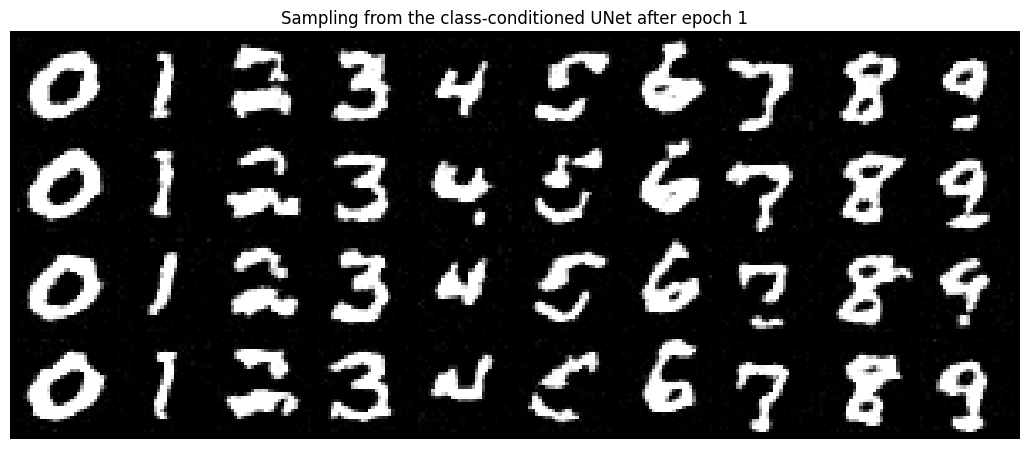

Saved checkpoint after epoch 1 to: checkpoints/ccfm_epoch_1.pt
Beginning epoch 2/10


100%|██████████| 938/938 [00:37<00:00, 25.12it/s]


Evaluating model on test set after epoch 2/10


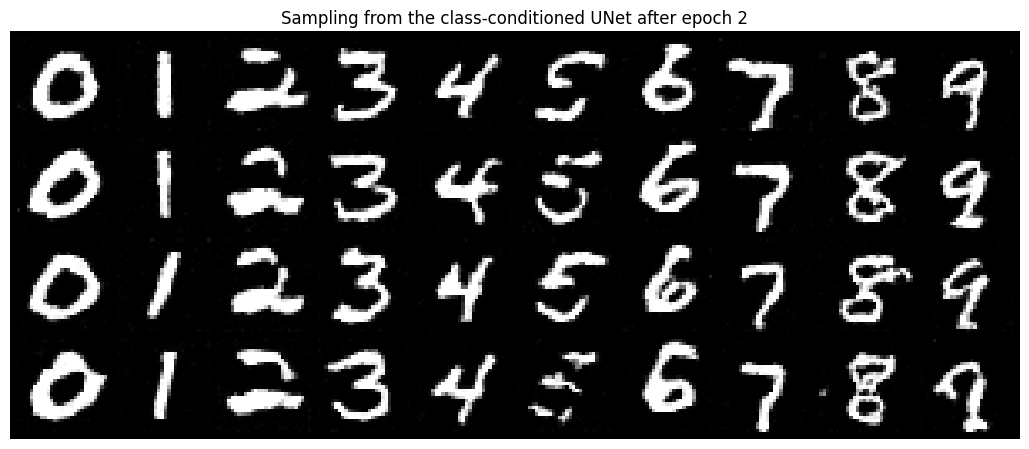

Beginning epoch 3/10


100%|██████████| 938/938 [00:37<00:00, 24.98it/s]


Evaluating model on test set after epoch 3/10


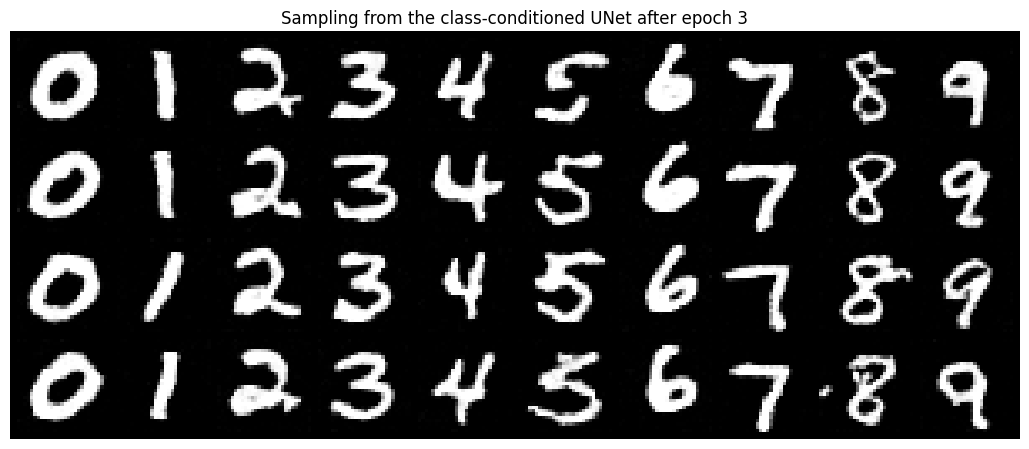

Beginning epoch 4/10


100%|██████████| 938/938 [00:37<00:00, 24.93it/s]


Evaluating model on test set after epoch 4/10


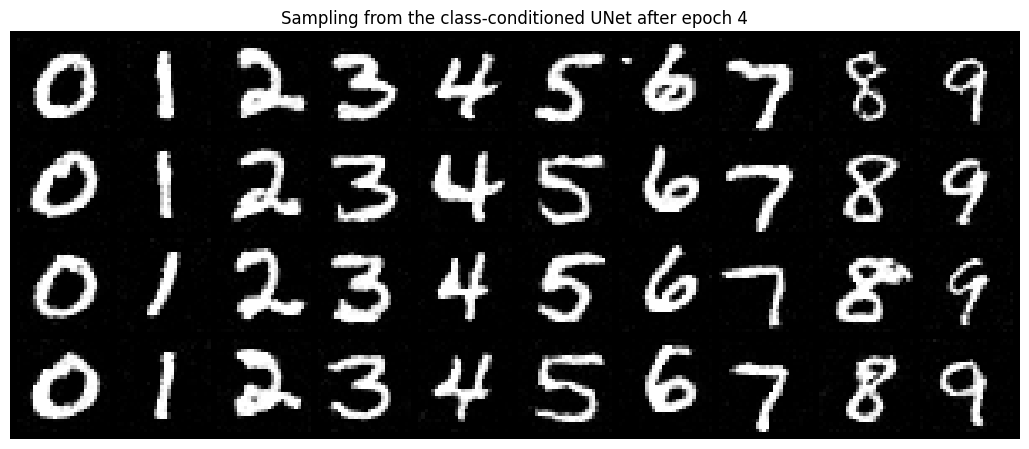

Beginning epoch 5/10


100%|██████████| 938/938 [00:37<00:00, 24.81it/s]


Evaluating model on test set after epoch 5/10


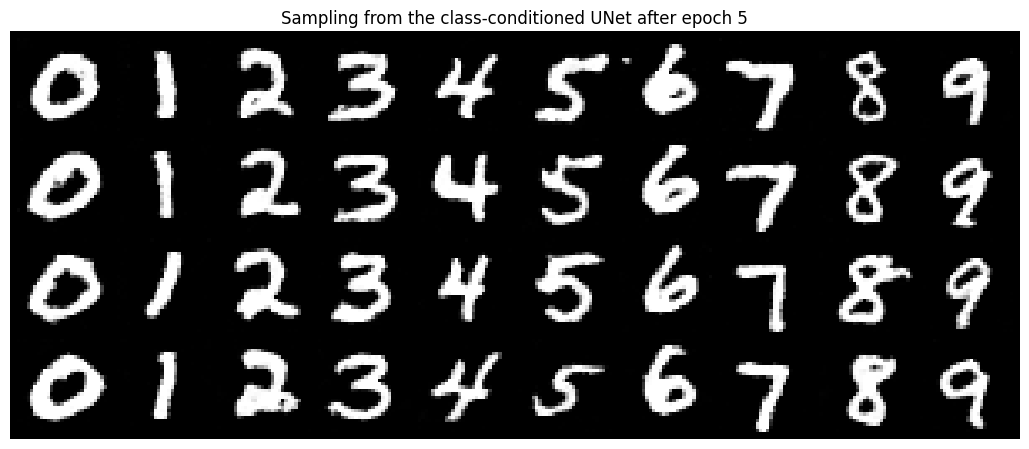

Saved checkpoint after epoch 5 to: checkpoints/ccfm_epoch_5.pt
Beginning epoch 6/10


100%|██████████| 938/938 [00:37<00:00, 24.69it/s]


Evaluating model on test set after epoch 6/10


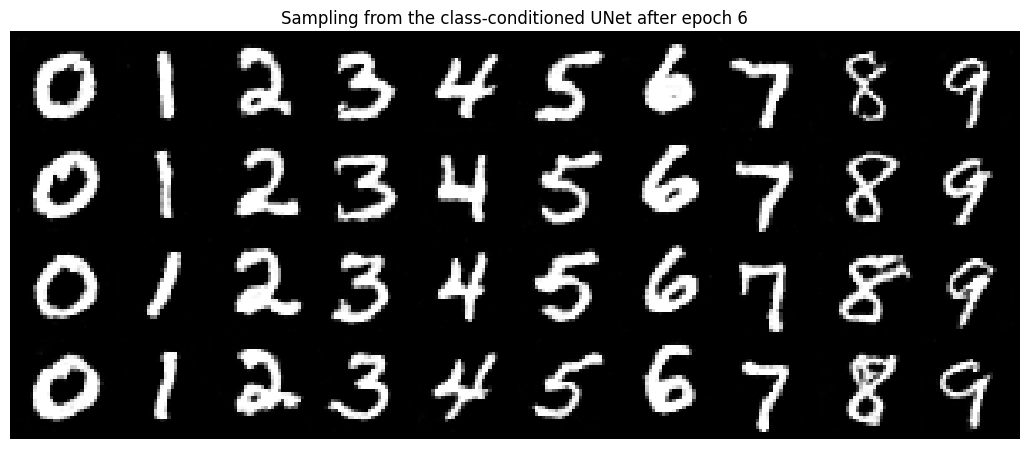

Beginning epoch 7/10


100%|██████████| 938/938 [00:38<00:00, 24.66it/s]


Evaluating model on test set after epoch 7/10


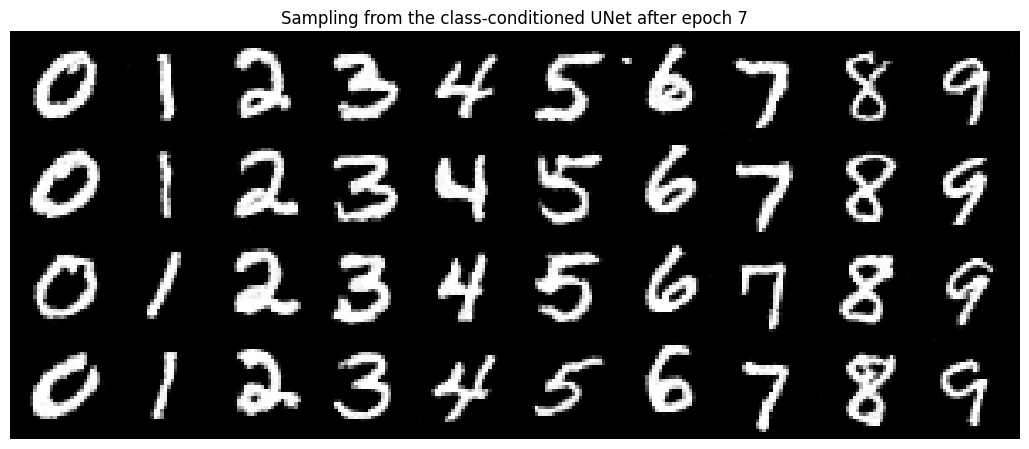

Beginning epoch 8/10


100%|██████████| 938/938 [00:38<00:00, 24.63it/s]


Evaluating model on test set after epoch 8/10


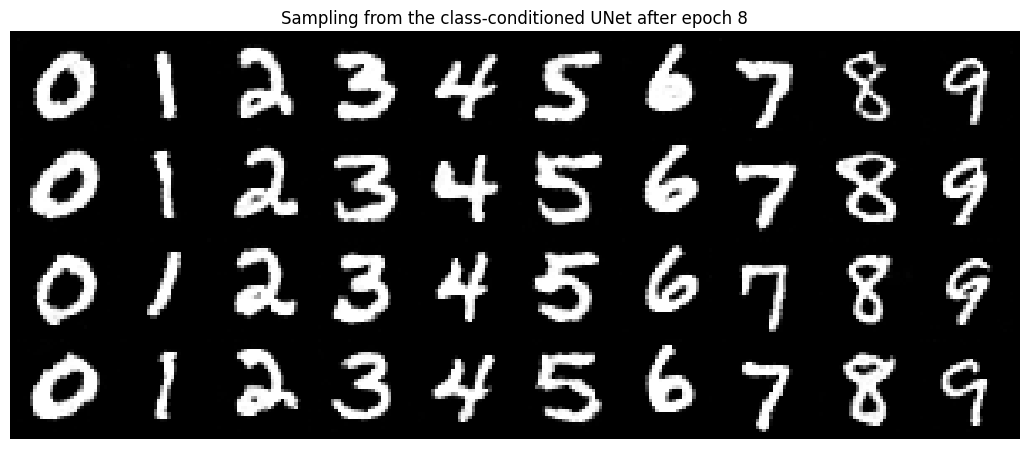

Beginning epoch 9/10


100%|██████████| 938/938 [00:38<00:00, 24.64it/s]


Evaluating model on test set after epoch 9/10


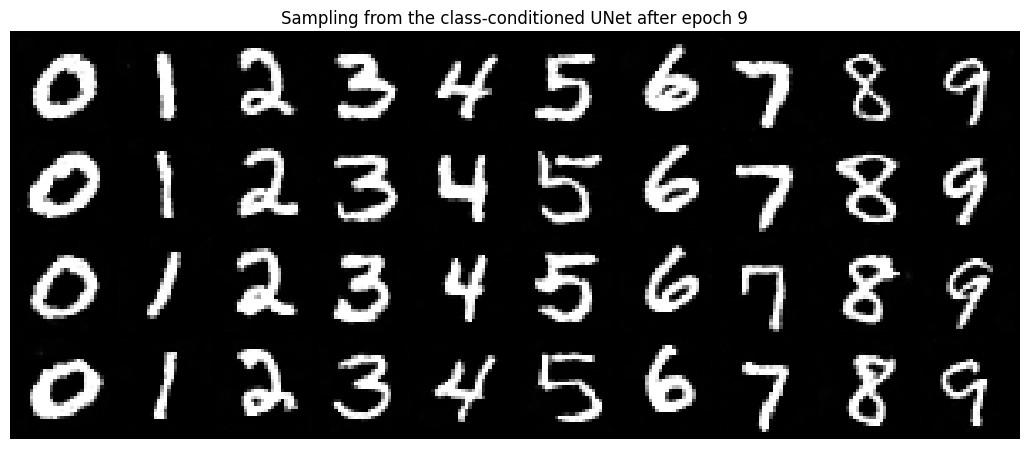

Beginning epoch 10/10


100%|██████████| 938/938 [00:38<00:00, 24.64it/s]


Evaluating model on test set after epoch 10/10


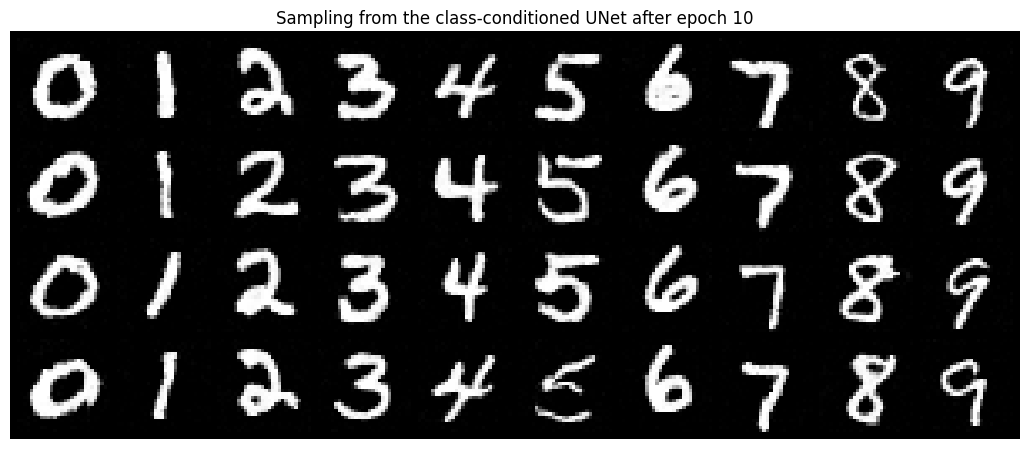

Saved checkpoint after epoch 10 to: checkpoints/ccfm_epoch_10.pt


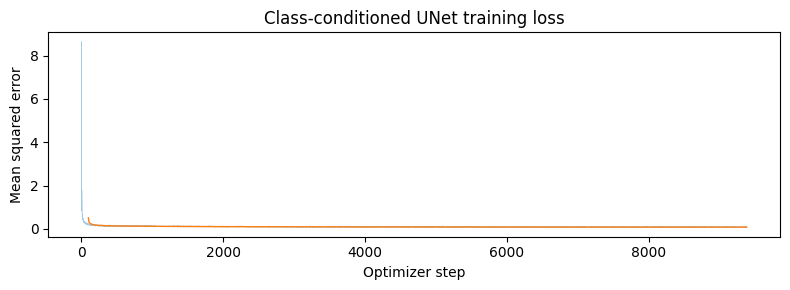

In [41]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.

# Set hyperparameters
batch_size = 64
learning_rate = 1e-2
hidden_dim = 64
num_epochs = 10
class_dropout_prob = 0.1

# Prepare data
gen = torch.Generator().manual_seed(SEED)  # Set seeded generator for reproducibility
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, generator=gen)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

# Initialize model
cc_unet = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim)
ccfm = ClassConditionalFM(cc_unet, num_ts=300, p_uncond=class_dropout_prob)
ccfm = ccfm.to(device)
ccfm_optimizer = torch.optim.Adam(ccfm.parameters(), lr=learning_rate)
ccfm_scheduler = torch.optim.lr_scheduler.ExponentialLR(ccfm_optimizer, gamma=(0.1 ** (1.0 / num_epochs)))

ccfm_train_losses = []
ccfm_test_losses = []
ccfm_samples_by_epoch = {}
NUM_SAMPLES = 40  # Number of images to sample after each epoch

for epoch in range(num_epochs):
  ccfm.train()
  print(f"Beginning epoch {epoch + 1}/{num_epochs}")
  for i, (x1, c) in enumerate(tqdm(train_loader)):
    x1 = x1.to(device)
    c = c.to(device)

    ccfm_optimizer.zero_grad()
    loss = ccfm(x1, c)
    loss.backward()
    ccfm_optimizer.step()
    ccfm_train_losses.append(loss.item())

  print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
  ccfm.eval()
  test_results = {
      "clean": [],
      "input": [],
      "prediction": []
  }
  with torch.no_grad():
      for x1, c in test_loader:
        x1 = x1.to(device)
        c = c.to(device=device)

        loss = ccfm(x1, c)
        ccfm_test_losses.append(loss.item())

      # Sample new images from the trained time-conditioned unet, starting from pure noise
      samples = []
      # Sample from classes 0-9, circling back to 0, for a total of NUM_SAMPLE samples
      sample_classes = (torch.arange(NUM_SAMPLES, device=device, dtype=torch.long) % cc_unet.num_classes)
      samples, _ = ccfm.sample(
          c=sample_classes,
          img_hw=(28, 28),
          guidance_scale=5.0,
          seed=SEED
      )

      show_grid(samples, f"Sampling from the class-conditioned UNet after epoch {epoch + 1}", f"ccfm_samples_epoch{epoch + 1}.jpg", images_per_row=10)
      ccfm_samples_by_epoch[epoch] = samples

  ccfm_scheduler.step()

  if (epoch + 1) in {1, 5, 10}:
    checkpoint_dir = Path("checkpoints")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    save_path = checkpoint_dir / f"ccfm_epoch_{epoch + 1}.pt"

    torch.save(
        {
            "completed_epochs": epoch + 1,
            "model": ccfm.state_dict(),
            "optimizer": ccfm_optimizer.state_dict(),
            "scheduler": ccfm_scheduler.state_dict(),
        },
        save_path
    )

    print(f"Saved checkpoint after epoch {epoch + 1} to: {save_path}")

loss_plot(ccfm_train_losses, "Class-conditioned UNet training loss")

Beginning epoch 1/10


100%|██████████| 938/938 [00:37<00:00, 25.17it/s]


Evaluating model on test set after epoch 1/10


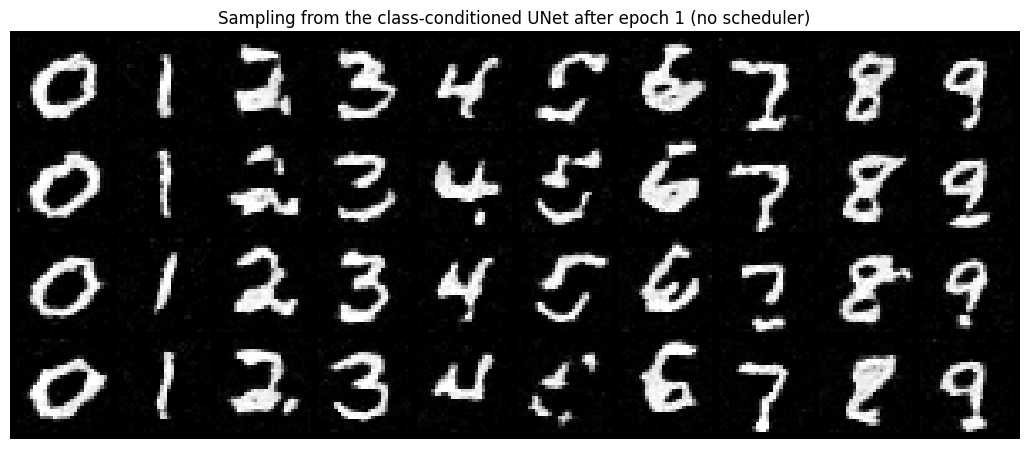

Saved checkpoint after epoch 1 to: checkpoints/ccfm_nosched_epoch_1.pt
Beginning epoch 2/10


100%|██████████| 938/938 [00:37<00:00, 25.08it/s]


Evaluating model on test set after epoch 2/10


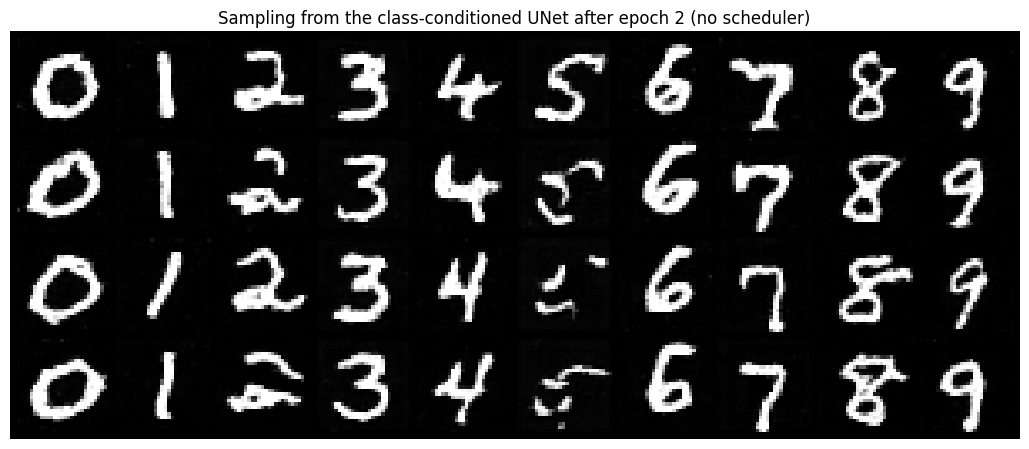

Beginning epoch 3/10


100%|██████████| 938/938 [00:37<00:00, 25.07it/s]


Evaluating model on test set after epoch 3/10


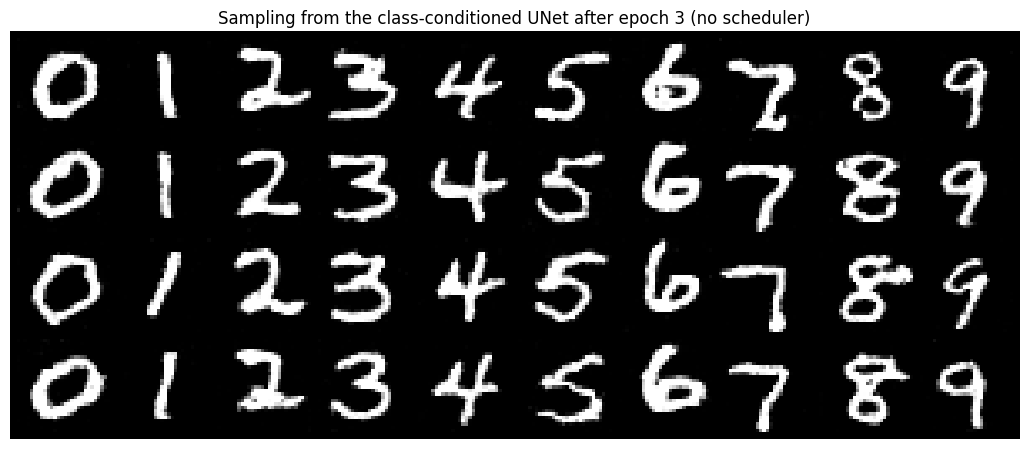

Beginning epoch 4/10


100%|██████████| 938/938 [00:37<00:00, 24.92it/s]


Evaluating model on test set after epoch 4/10


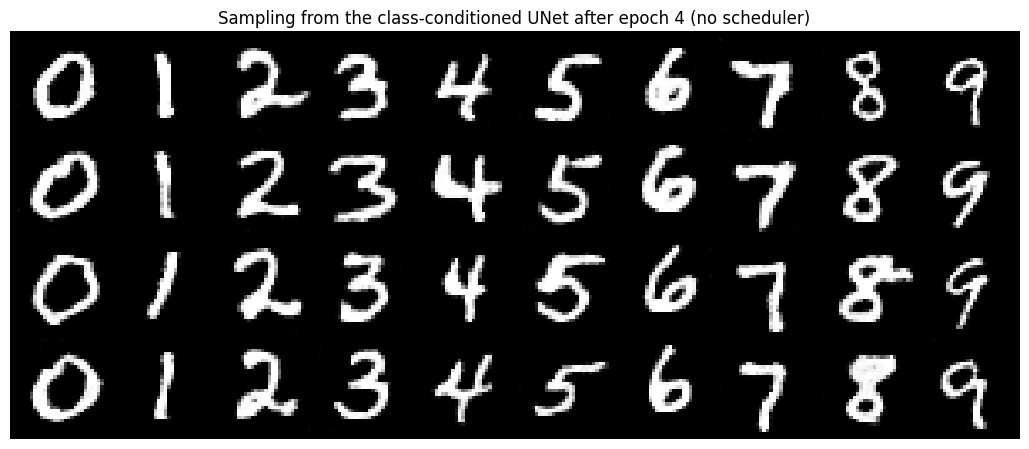

Beginning epoch 5/10


100%|██████████| 938/938 [00:37<00:00, 24.73it/s]


Evaluating model on test set after epoch 5/10


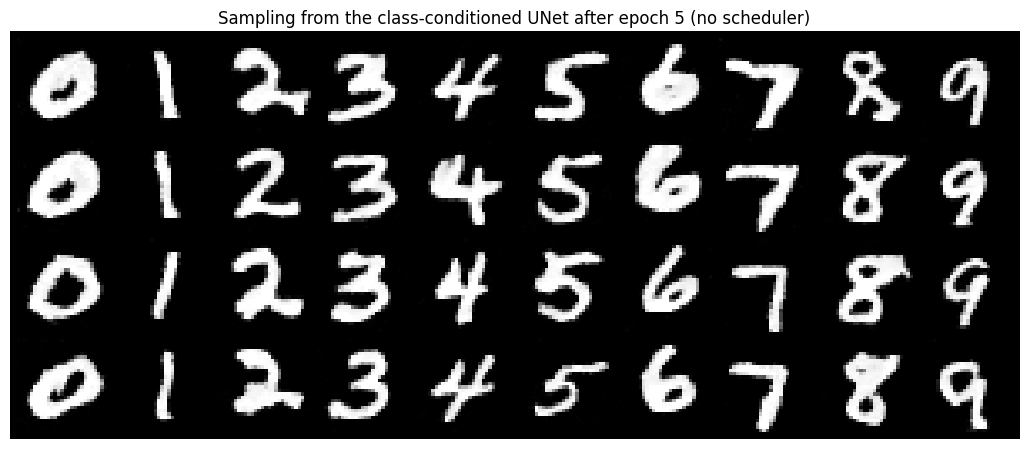

Saved checkpoint after epoch 5 to: checkpoints/ccfm_nosched_epoch_5.pt
Beginning epoch 6/10


100%|██████████| 938/938 [00:38<00:00, 24.66it/s]


Evaluating model on test set after epoch 6/10


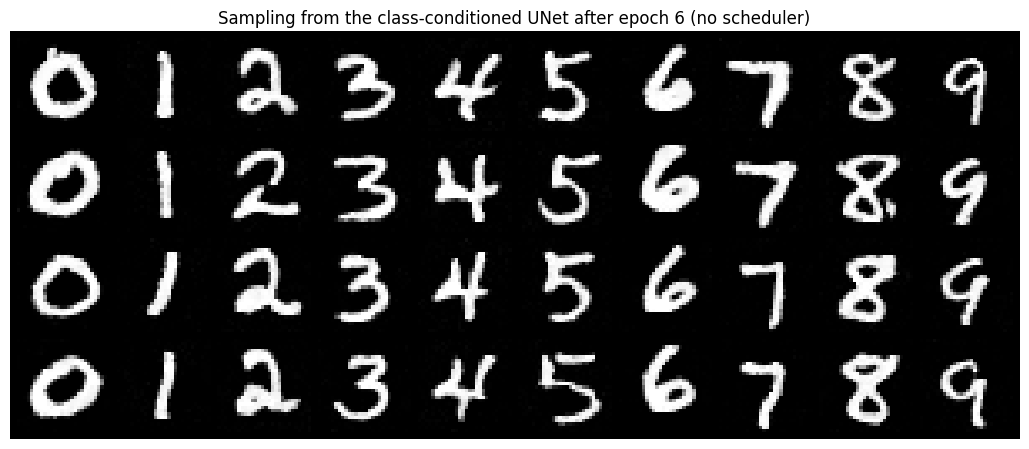

Beginning epoch 7/10


100%|██████████| 938/938 [00:38<00:00, 24.67it/s]


Evaluating model on test set after epoch 7/10


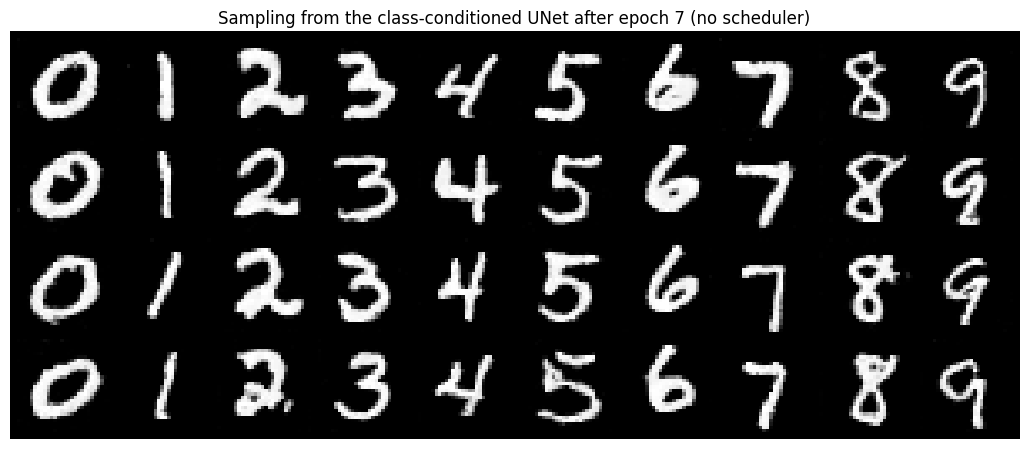

Beginning epoch 8/10


100%|██████████| 938/938 [00:38<00:00, 24.65it/s]


Evaluating model on test set after epoch 8/10


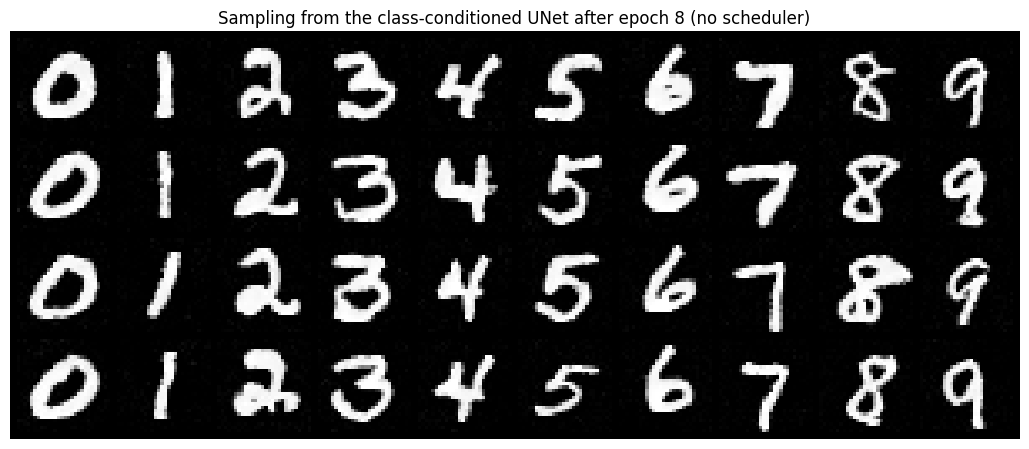

Beginning epoch 9/10


100%|██████████| 938/938 [00:38<00:00, 24.61it/s]


Evaluating model on test set after epoch 9/10


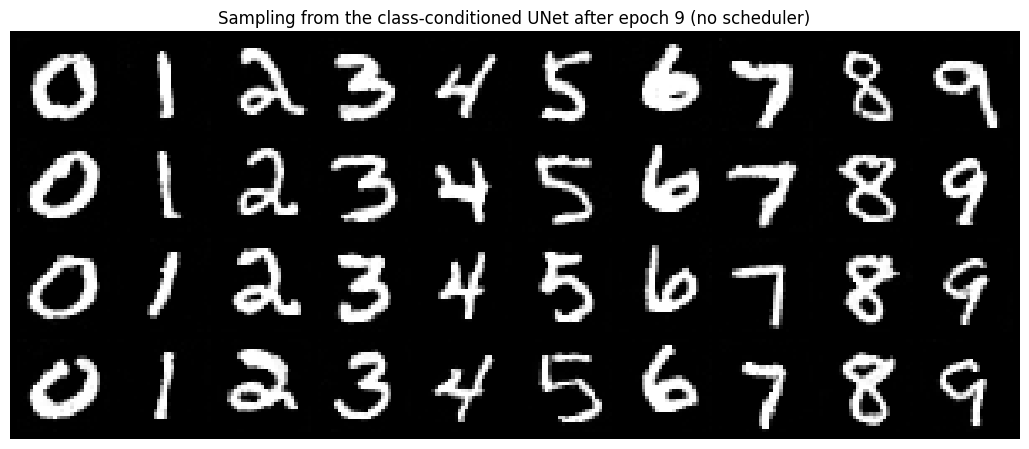

Beginning epoch 10/10


100%|██████████| 938/938 [00:38<00:00, 24.58it/s]


Evaluating model on test set after epoch 10/10


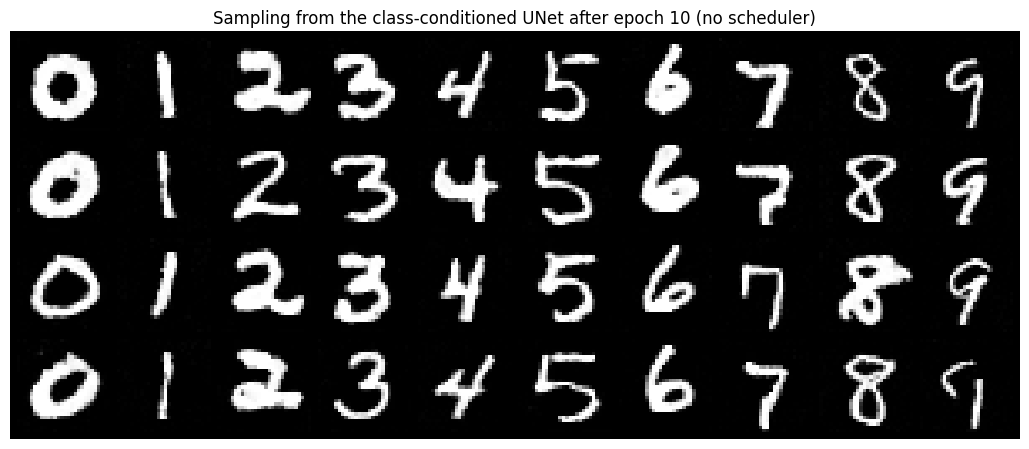

Saved checkpoint after epoch 10 to: checkpoints/ccfm_nosched_epoch_10.pt


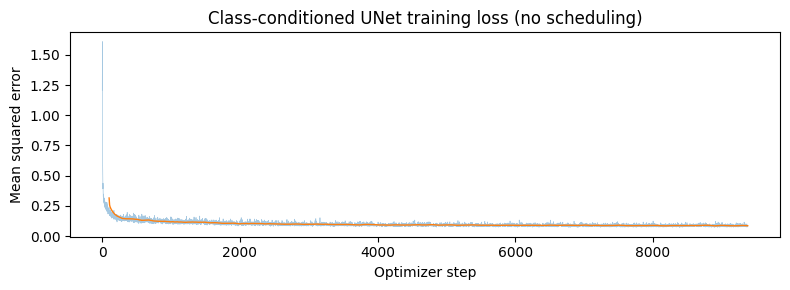

In [42]:
# No-scheduler flow model for comparison;
# choose/document a constant learning rate and compare results.

# Set hyperparameters
batch_size = 64
learning_rate = 1e-2
hidden_dim = 64
num_epochs = 10
class_dropout_prob = 0.1

# Prepare data
gen = torch.Generator().manual_seed(SEED)  # Set seeded generator for reproducibility
train_loader = DataLoader(train_dataset, batch_size, shuffle=True, generator=gen)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

# Initialize model
cc_unet_nosched = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim)
ccfm_nosched = ClassConditionalFM(cc_unet_nosched, num_ts=300, p_uncond=class_dropout_prob)
ccfm_nosched = ccfm_nosched.to(device)
ccfm_nosched_optimizer = torch.optim.Adam(ccfm_nosched.parameters(), lr=learning_rate)

ccfm_nosched_train_losses = []
ccfm_nosched_test_losses = []
ccfm_nosched_samples_by_epoch = {}
NUM_SAMPLES = 40  # Number of images to sample after each epoch

for epoch in range(num_epochs):
  ccfm_nosched.train()
  print(f"Beginning epoch {epoch + 1}/{num_epochs}")
  for i, (x1, c) in enumerate(tqdm(train_loader)):
    x1 = x1.to(device)
    c = c.to(device)

    ccfm_nosched_optimizer.zero_grad()
    loss = ccfm_nosched(x1, c)
    loss.backward()
    ccfm_nosched_optimizer.step()
    ccfm_nosched_train_losses.append(loss.item())

  print(f"Evaluating model on test set after epoch {epoch + 1}/{num_epochs}")
  ccfm_nosched.eval()
  test_results = {
      "clean": [],
      "input": [],
      "prediction": []
  }
  with torch.no_grad():
      for x1, c in test_loader:
        x1 = x1.to(device)
        c = c.to(device=device)

        loss = ccfm_nosched(x1, c)
        ccfm_nosched_test_losses.append(loss.item())

      # Sample new images from the trained time-conditioned unet, starting from pure noise
      samples = []
      # Sample from classes 0-9, circling back to 0, for a total of NUM_SAMPLE samples
      sample_classes = (torch.arange(NUM_SAMPLES, device=device, dtype=torch.long) % cc_unet_nosched.num_classes)
      samples, _ = ccfm_nosched.sample(
          c=sample_classes,
          img_hw=(28, 28),
          guidance_scale=5.0,
          seed=SEED
      )

      show_grid(samples, f"Sampling from the class-conditioned UNet after epoch {epoch + 1} (no scheduler)", f"ccfm_nosched_samples_epoch{epoch + 1}.jpg", images_per_row=10)
      ccfm_nosched_samples_by_epoch[epoch] = samples

  if (epoch + 1) in {1, 5, 10}:
    checkpoint_dir = Path("checkpoints")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    save_path = checkpoint_dir / f"ccfm_nosched_epoch_{epoch + 1}.pt"

    torch.save(
        {
            "completed_epochs": epoch + 1,
            "model": ccfm_nosched.state_dict(),
            "optimizer": ccfm_nosched_optimizer.state_dict(),
        },
        save_path
    )

    print(f"Saved checkpoint after epoch {epoch + 1} to: {save_path}")

loss_plot(ccfm_nosched_train_losses, "Class-conditioned UNet training loss (no scheduling)")

# Part 2.6: Sampling from the Class-conditioned UNet

In [42]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.

ccfm_epoch1_checkpoint = torch.load(
    "checkpoints/ccfm_epoch_1.pt",
    map_location=device,
    weights_only=True
)

cc_unet_epoch1 = ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=hidden_dim)
ccfm_epoch1 = ClassConditionalFM(cc_unet_epoch1, num_ts=300, p_uncond=class_dropout_prob)
ccfm_epoch1.load_state_dict(ccfm_epoch1_checkpoint["model"])
ccfm_epoch1.eval()